In [10]:
import matplotlib.pyplot as plt



In [11]:
pip install pathlib


Note: you may need to restart the kernel to use updated packages.


In [12]:
import joblib
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import numpy as np

In [13]:
df= pd.read_csv(r"C:\Users\keert\OneDrive\Desktop\Projects\AGENT WORK\StudentPerformanceFactors.csv")

In [14]:
df


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [15]:
print("dataset shape:",df.shape)
print(df.head())
print("\nMissing values:")
print(df.isnull().sum())

dataset shape: (6607, 20)
   Hours_Studied  Attendance Parental_Involvement Access_to_Resources  \
0             23          84                  Low                High   
1             19          64                  Low              Medium   
2             24          98               Medium              Medium   
3             29          89                  Low              Medium   
4             19          92               Medium              Medium   

  Extracurricular_Activities  Sleep_Hours  Previous_Scores Motivation_Level  \
0                         No            7               73              Low   
1                         No            8               59              Low   
2                        Yes            7               91           Medium   
3                        Yes            8               98           Medium   
4                        Yes            6               65           Medium   

  Internet_Access  Tutoring_Sessions Family_Income Teacher_Q

In [16]:
df.columns


Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='str')

In [17]:
# Count completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Missing values as percentages
missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percent)

# Numeric data summary
display(df.describe())

# Categorical data summary
display(df.describe(include="object"))

Duplicate rows: 0
Parental_Education_Level      1.362192
Teacher_Quality               1.180566
Distance_from_Home            1.014076
Hours_Studied                 0.000000
Access_to_Resources           0.000000
Parental_Involvement          0.000000
Attendance                    0.000000
Extracurricular_Activities    0.000000
Motivation_Level              0.000000
Internet_Access               0.000000
Previous_Scores               0.000000
Sleep_Hours                   0.000000
Family_Income                 0.000000
Tutoring_Sessions             0.000000
School_Type                   0.000000
Peer_Influence                0.000000
Learning_Disabilities         0.000000
Physical_Activity             0.000000
Gender                        0.000000
Exam_Score                    0.000000
dtype: float64


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


C:\Users\keert\AppData\Local\Temp\ipykernel_27324\2495766414.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Motivation_Level,Internet_Access,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
count,6607,6607,6607,6607,6607,6607,6529,6607,6607,6607,6517,6540,6607
unique,3,3,2,3,2,3,3,2,3,2,3,3,2
top,Medium,Medium,Yes,Medium,Yes,Low,Medium,Public,Positive,No,High School,Near,Male
freq,3362,3319,3938,3351,6108,2672,3925,4598,2638,5912,3223,3884,3814


In [18]:
missing_cols = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for col in missing_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


Teacher_Quality
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

Parental_Education_Level
Parental_Education_Level
High School     3223
College         1989
Postgraduate    1305
NaN               90
Name: count, dtype: int64

Distance_from_Home
Distance_from_Home
Near        3884
Moderate    1998
Far          658
NaN           67
Name: count, dtype: int64


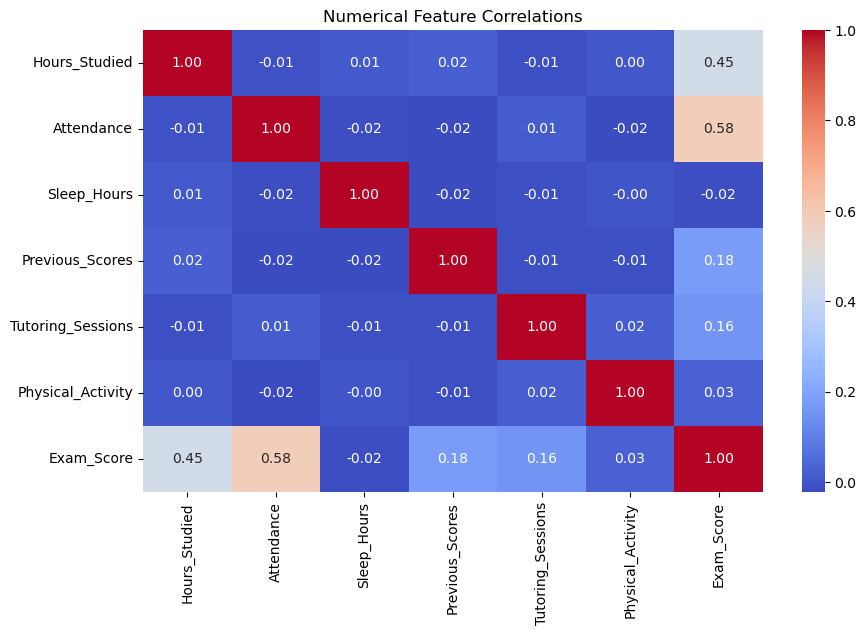

In [19]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Numerical Feature Correlations")
plt.show()

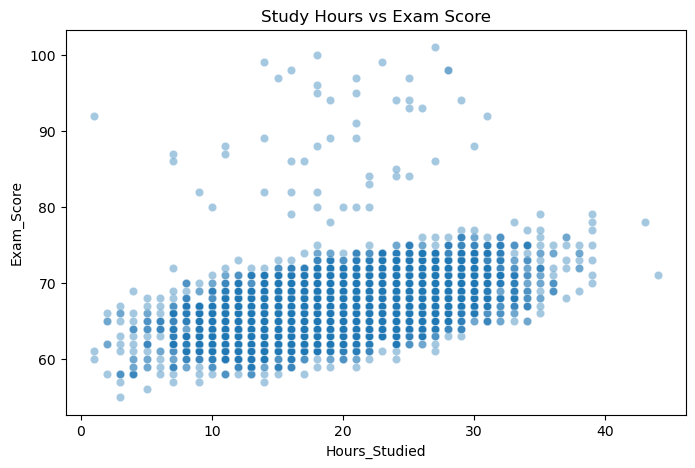

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Hours_Studied",
    y="Exam_Score",
    alpha=0.4
)

plt.title("Study Hours vs Exam Score")
plt.show()

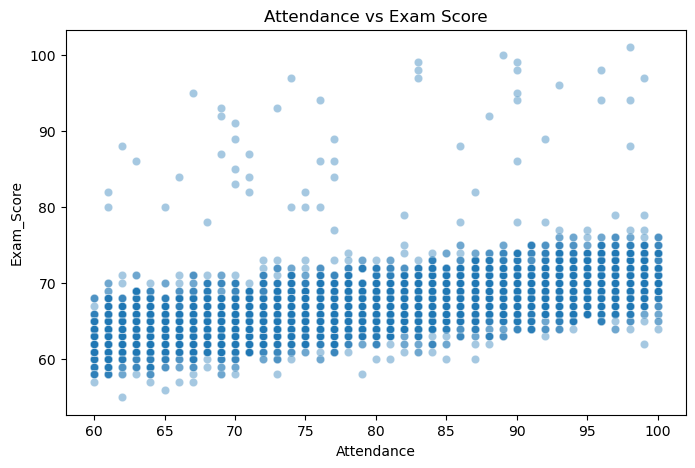

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Attendance",
    y="Exam_Score",
    alpha=0.4
)

plt.title("Attendance vs Exam Score")
plt.show()

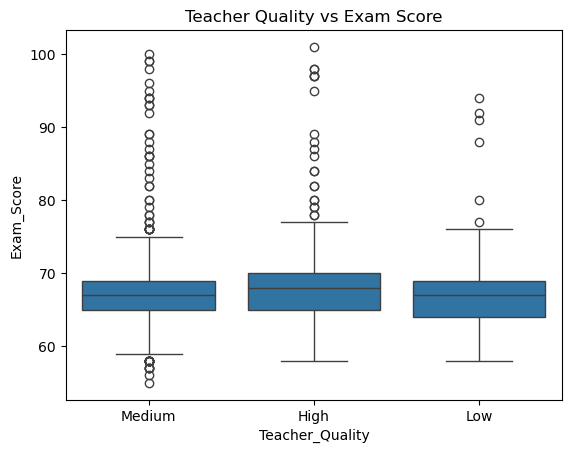

In [22]:
sns.boxplot(
    data=df,
    x="Teacher_Quality",
    y="Exam_Score"
)

plt.title("Teacher Quality vs Exam Score")
plt.show()

In [23]:
# 1. Data types
print(df.dtypes)

# 2. Duplicate count
print(df.duplicated().sum())

# 3. Numerical correlations with target
print(
    df.corr(numeric_only=True)["Exam_Score"]
      .sort_values(ascending=False)
)

Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disabilities           str
Parental_Education_Level        str
Distance_from_Home              str
Gender                          str
Exam_Score                    int64
dtype: object
0
Exam_Score           1.000000
Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


In [24]:
import pandas as pd

categorical_cols = df.select_dtypes(
    include=["object", "str", "category"]
).columns

for col in categorical_cols:
    print(f"\n{col}")
    print(
        df.groupby(col, dropna=False)["Exam_Score"]
          .agg(["count", "mean"])
          .round(2)
          .sort_values("mean", ascending=False)
    )


Parental_Involvement
                      count   mean
Parental_Involvement              
High                   1908  68.09
Medium                 3362  67.10
Low                    1337  66.36

Access_to_Resources
                     count   mean
Access_to_Resources              
High                  1975  68.09
Medium                3319  67.13
Low                   1313  66.20

Extracurricular_Activities
                            count   mean
Extracurricular_Activities              
Yes                          3938  67.44
No                           2669  66.93

Motivation_Level
                  count   mean
Motivation_Level              
High               1319  67.70
Medium             3351  67.33
Low                1937  66.75

Internet_Access
                 count   mean
Internet_Access              
Yes               6108  67.29
No                 499  66.54

Family_Income
               count   mean
Family_Income              
High            1269  67.84
Medium     

In [25]:
numerical_features = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity"
]

ordinal_features = [
    "Parental_Involvement",
    "Access_to_Resources",
    "Motivation_Level",
    "Family_Income",
    "Teacher_Quality",
    "Peer_Influence",
    "Parental_Education_Level",
    "Distance_from_Home"
]

nominal_features = [
    "Extracurricular_Activities",
    "Internet_Access",
    "School_Type",
    "Learning_Disabilities",
    "Gender"
]

In [26]:
X = df.drop(columns=["Exam_Score"])
y = df["Exam_Score"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Categorical: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [27]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [28]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Before encoding:", X_train.shape)
print("After encoding:", X_train_processed.shape)



Before encoding: (5285, 19)
After encoding: (5285, 40)


In [29]:
# Get encoded column names
feature_names = preprocessor.get_feature_names_out()

# Convert processed array into DataFrame
X_train_encoded = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Display first 5 rows
display(X_train_encoded.head())

,num__Hours_Studied,num__Attendance,num__Sleep_Hours,num__Previous_Scores,num__Tutoring_Sessions,num__Physical_Activity,cat__Parental_Involvement_High,cat__Parental_Involvement_Low,cat__Parental_Involvement_Medium,cat__Access_to_Resources_High,...,cat__Learning_Disabilities_No,cat__Learning_Disabilities_Yes,cat__Parental_Education_Level_College,cat__Parental_Education_Level_High School,cat__Parental_Education_Level_Postgraduate,cat__Distance_from_Home_Far,cat__Distance_from_Home_Moderate,cat__Distance_from_Home_Near,cat__Gender_Female,cat__Gender_Male
5810,1.173579,-0.075846,0.669094,-0.837277,0.405784,1.964909,0.0,1.0,0.0,1.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
1268,-0.661983,0.531894,-0.016740,1.314728,0.405784,0.030381,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
414,0.339232,0.618714,0.669094,0.551113,-0.405017,-1.904146,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4745,-0.328245,1.747376,2.040764,0.759372,-0.405017,0.030381,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
654,2.508533,-0.162667,2.040764,1.661825,-0.405017,-0.936882,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0


In [30]:
print("Original features:", X_train.shape[1])
print("Encoded features:", X_train_encoded.shape[1])

print("Missing values:",
      X_train_encoded.isnull().sum().sum())

print("All numerical:",
      all(pd.api.types.is_numeric_dtype(dtype)
          for dtype in X_train_encoded.dtypes))

Original features: 19
Encoded features: 40
Missing values: 0
All numerical: True


In [31]:
lr_model= LinearRegression()

lr_model.fit(X_train_processed,y_train)

print( "Linear Regression Trained successfully!")

Linear Regression Trained successfully!


In [33]:
from sklearn.pipeline import Pipeline


lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [34]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

mae_scores = -scores

print("MAE for each fold:", mae_scores)
print("Average MAE:", mae_scores.mean())
print("Standard Deviation:", mae_scores.std())

MAE for each fold: [0.45459405 0.43685747 0.50850265 0.52180711 0.6139745 ]
Average MAE: 0.5071471541182364
Standard Deviation: 0.06217925994501193


In [35]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

rf_mae_scores = -rf_scores

print("Random Forest MAE:", rf_mae_scores)
print("Average MAE:", rf_mae_scores.mean())
print("Standard Deviation:", rf_mae_scores.std())

Random Forest MAE: [1.10487228 1.11384106 1.18107852 1.19518448 1.26832545]
Average MAE: 1.1726603595080416
Standard Deviation: 0.05964049778128858


In [36]:
best_model = lr_pipeline

best_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Hours_Studied',
                                                   'Attendance', 'Sleep_Hours',
                                                   'Previous_Scores',
                                                   'Tutoring_Sessions',
                                                   'Physical_Activity']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Parental_Involvement',
                                                   'Access_to_Resources',
                                                   'Extracurricular_Activities',
                                                   'Motivation_Level',
                                                   'Internet_Access',
                                                   'Family_Income',
                                                   'Teacher_Quality',
                                                   'School_Type',
                                                   'Peer_Influence',
                                                   'Learning_Disabilities',
                                                   'Parental_Education_Level',
                                                   'Distance_from_Home',
                                                   'Gender'])])),
                ('model', LinearRegression())])

In [37]:
y_pred = best_model.predict(X_test)

In [38]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Final Test Results")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

Final Test Results
MAE: 0.4524
RMSE: 1.8044
R2 Score: 0.7696


In [39]:
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Hours_Studied',
                                                   'Attendance', 'Sleep_Hours',
                                                   'Previous_Scores',
                                                   'Tutoring_Sessions',
                                                   'Physical_Activity']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Parental_Involvement',
                                                   'Access_to_Resources',
                                                   'Extracurricular_Activities',
                                                   'Motivation_Level',
                                                   'Internet_Access',
                                                   'Family_Income',
                                                   'Teacher_Quality',
                                                   'School_Type',
                                                   'Peer_Influence',
                                                   'Learning_Disabilities',
                                                   'Parental_Education_Level',
                                                   'Distance_from_Home',
                                                   'Gender'])])),
                ('model', RandomForestRegressor(n_jobs=-1, random_state=42))])

In [40]:
y_pred_rf = rf_pipeline.predict(X_test)

In [42]:
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("Final Test Results")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

Final Test Results
MAE: 1.0792
RMSE: 2.156
R2 Score: 0.6712


In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame({
    "Linear Regression": evaluate_model(y_test, y_pred),
    "Random Forest": evaluate_model(y_test, y_pred_rf)
}).T

display(results.round(4))

,MAE,RMSE,R2
Linear Regression,0.4524,1.8044,0.7696
Random Forest,1.0792,2.1560,0.6712


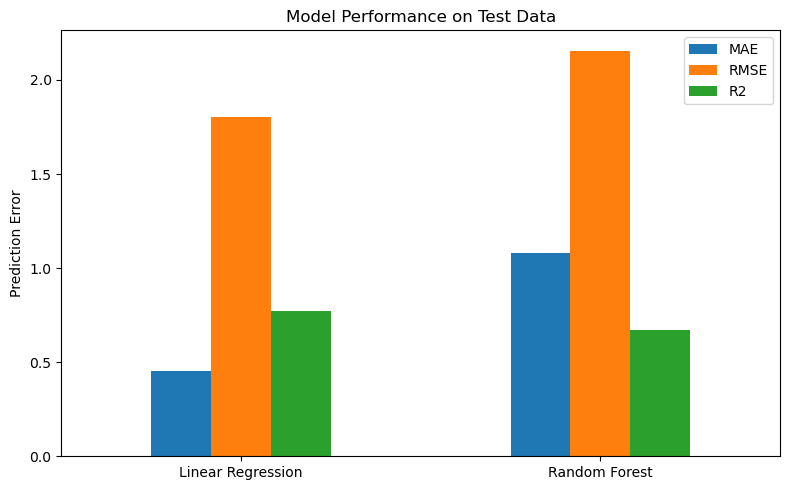

In [70]:
import matplotlib.pyplot as plt

results[["MAE", "RMSE","R2"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Performance on Test Data")
plt.ylabel("Prediction Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [45]:
error_analysis = pd.DataFrame({
    "Actual_Score": y_test,
    "Predicted_Score": y_pred
})

error_analysis["Absolute_Error"] = abs(
    error_analysis["Actual_Score"] -
    error_analysis["Predicted_Score"]
)

# Show the 10 predictions with largest errors
display(
    error_analysis.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

,Actual_Score,Predicted_Score,Absolute_Error
217,89,60.989759,28.010241
4192,98,70.902730,27.097270
2687,87,60.105764,26.894236
4531,93,67.554328,25.445672
5966,97,73.039858,23.960142
2513,88,68.007096,19.992904
5989,80,64.929614,15.070386
5725,65,66.570881,1.570881
3543,57,58.119570,1.119570
3686,67,68.098534,1.098534


In [46]:
# Copy the original test records
error_details = X_test.copy()

# Add actual and predicted scores
error_details["Actual_Score"] = y_test
error_details["Predicted_Score"] = y_pred

# Calculate error
error_details["Absolute_Error"] = abs(
    error_details["Actual_Score"] -
    error_details["Predicted_Score"]
)

# Display the 10 largest errors
display(
    error_details.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,...,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Actual_Score,Predicted_Score,Absolute_Error
217,19,70,Medium,Low,No,7,54,High,Yes,0,...,Public,Positive,2,Yes,High School,Moderate,Male,89,60.989759,28.010241
4192,28,90,Low,Medium,Yes,9,91,Medium,Yes,0,...,Public,Positive,2,No,College,Moderate,Female,98,70.902730,27.097270
2687,11,71,Low,Medium,Yes,8,55,Medium,Yes,1,...,Public,Negative,3,No,College,Near,Female,87,60.105764,26.894236
4531,26,69,High,High,No,7,95,Low,No,0,...,Public,Negative,3,No,Postgraduate,Near,Female,93,67.554328,25.445672
5966,25,99,Medium,Medium,Yes,7,77,Medium,Yes,0,...,Public,Neutral,3,No,High School,Near,Male,97,73.039858,23.960142
2513,18,86,High,Medium,No,8,60,Medium,Yes,2,...,Private,Neutral,1,No,College,Near,Male,88,68.007096,19.992904
5989,18,61,Medium,Low,Yes,6,91,High,Yes,3,...,Public,Positive,3,No,College,Moderate,Female,80,64.929614,15.070386
5725,13,73,Medium,High,No,8,93,Medium,Yes,0,...,Public,Neutral,3,No,Postgraduate,NaN,Female,65,66.570881,1.570881
3543,14,67,Low,Low,Yes,7,66,Low,Yes,0,...,Public,Neutral,4,No,High School,Far,Female,57,58.119570,1.119570
3686,35,68,Low,High,Yes,5,64,Medium,Yes,0,...,Public,Positive,4,Yes,High School,Near,Male,67,68.098534,1.098534


In [50]:
errors = error_details["Absolute_Error"]

print("Error <= 2:", (errors <= 2).sum())

print("Error between 2 and 5:",
      ((errors > 2) & (errors <= 5)).sum())

print("Error between 5 and 10:",
      ((errors > 5) & (errors <= 10)).sum())

print("Error > 10:", (errors > 10).sum())

Error <= 2: 1315
Error between 2 and 5: 0
Error between 5 and 10: 0
Error > 10: 7


In [51]:
# Students with large errors
high_error = error_details[
    error_details["Absolute_Error"] > 10
]

# Students with smaller errors
normal_error = error_details[
    error_details["Absolute_Error"] <= 10
]

columns = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Actual_Score"
]

print("High-error students:")
display(high_error[columns].mean().round(2))

print("Other students:")
display(normal_error[columns].mean().round(2))

High-error students:


Hours_Studied        20.71
Attendance           78.00
Previous_Scores      74.71
Tutoring_Sessions     0.86
Actual_Score         90.29
dtype: float64

Other students:


Hours_Studied        20.00
Attendance           80.41
Previous_Scores      75.11
Tutoring_Sessions     1.47
Actual_Score         67.20
dtype: float64

In [52]:
display(high_error[columns])

,Hours_Studied,Attendance,Previous_Scores,Tutoring_Sessions,Actual_Score
217,19,70,54,0,89
2513,18,86,60,2,88
4192,28,90,91,0,98
5966,25,99,77,0,97
5989,18,61,91,3,80
2687,11,71,55,1,87
4531,26,69,95,0,93


In [53]:
# Extract the trained Linear Regression model
lr_model = lr_pipeline.named_steps["model"]

# Extract the fitted preprocessor
fitted_preprocessor = lr_pipeline.named_steps["preprocessor"]

# Get feature names after encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Get learned coefficients
coefficients = lr_model.coef_

print("Number of features:", len(feature_names))
print("Number of coefficients:", len(coefficients))
print("Intercept:", lr_model.intercept_)

Number of features: 40
Number of coefficients: 40
Intercept: 66.15936080553368


In [54]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Coefficient,Absolute_Coefficient
1,num__Attendance,2.290405,2.290405
0,num__Hours_Studied,1.756881,1.756881
10,cat__Access_to_Resources_Low,-1.056906,1.056906
9,cat__Access_to_Resources_High,1.044244,1.044244
6,cat__Parental_Involvement_High,1.023711,1.023711
7,cat__Parental_Involvement_Low,-0.977973,0.977973
3,num__Previous_Scores,0.705908,0.705908
4,num__Tutoring_Sessions,0.626224,0.626224
19,cat__Family_Income_High,0.582719,0.582719
27,cat__Peer_Influence_Negative,-0.539524,0.539524


In [65]:
import joblib
from pathlib import Path

# Fit final selected model on full training dataset
lr_pipeline.fit(X_train, y_train)

# Create models directory if it doesn't exist
Path("models").mkdir(exist_ok=True)

# Save preprocessing + model together
joblib.dump(
    lr_pipeline,
    "models/student_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [66]:
# Load saved pipeline
loaded_model = joblib.load(
    "models/student_model.pkl"
)

# Select one student from our test data
sample_student = X_test.iloc[[0]]

# Make a prediction
predicted_score = loaded_model.predict(
    sample_student
)

print("Predicted Score:", predicted_score[0])
print("Actual Score:", y_test.iloc[0])

Predicted Score: 64.52628301574251
Actual Score: 65


In [67]:
import os

print(os.getcwd())
print(os.path.abspath("models/student_model.pkl"))

C:\Users\keert
C:\Users\keert\models\student_model.pkl


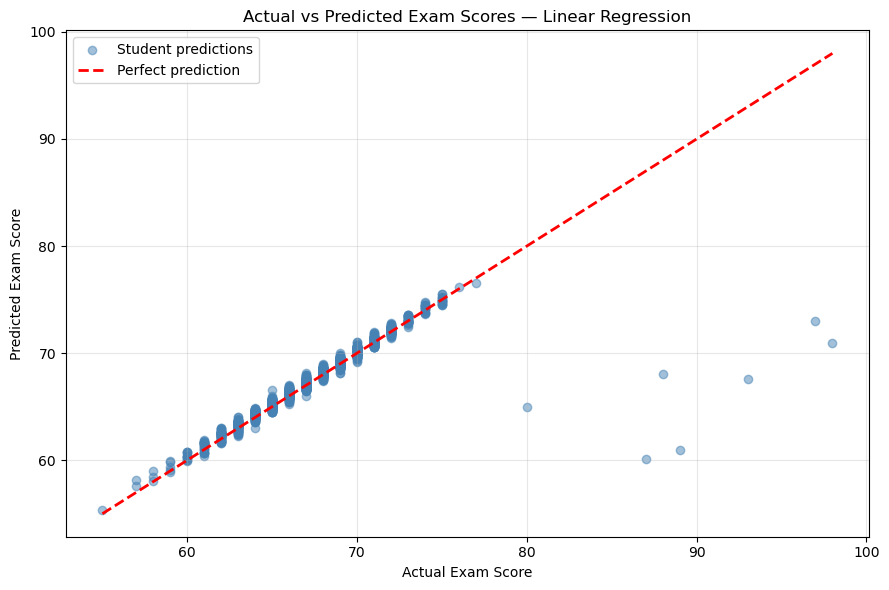

In [73]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

# Plot actual vs predicted scores
plt.scatter(
    y_test,
    y_pred,
    alpha=0.5,
    color="steelblue",
    label="Student predictions"
)

# Perfect prediction line
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores — Linear Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

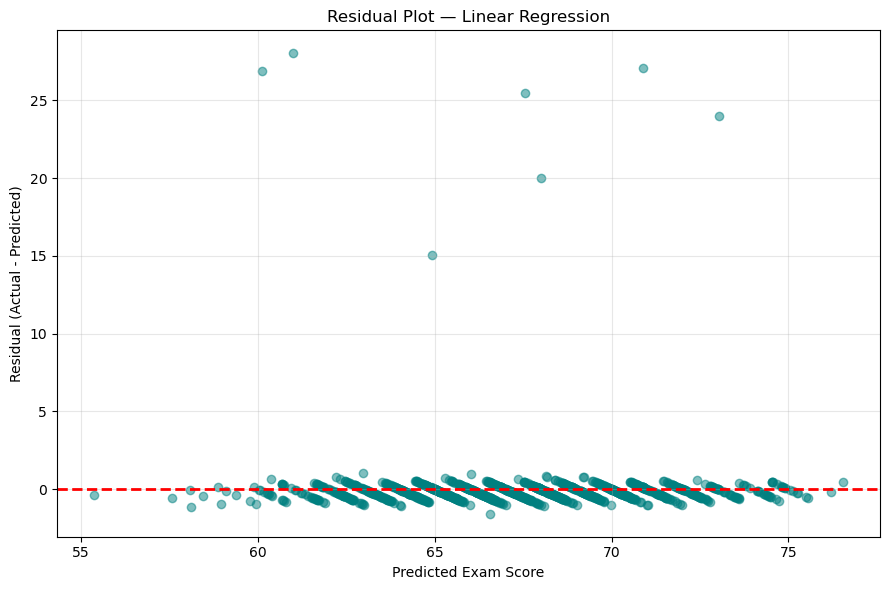

In [74]:
# Calculate residuals
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.5,
    color="teal"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted Exam Score")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot — Linear Regression")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()